# Q2C | Analyze Relationships Between Attributes

> *Analyze the relationships between the data attributes, and between the data attributes and label. This involves computing the Pearson Correlation Coefficient (PCC) and generating scatter plots.*

---

#### IMPORTANT

This dataset has no `train` / `test` split of its own, so the same chronological split as Q2B is made at the top of this notebook: the earliest 584 days are `train` and the latest 147 days are `test`. Every statistic and every score below is computed on the training rows only, so no analysis or treatment decision is influenced by the test data (`data snooping`).

# Answer Summary

**PCC and scatter plots:** a scatter matrix of the continuous attributes and `Rentals`, a Pearson (lower) vs Spearman (upper) correlation matrix of all 11 attributes and `Rentals`, and checks for redundant attributes. Then each attribute's shape is tested: a reshaped continuous attribute (hinge, indicator) or an encoded categorical one (one-hot, sine / cosine) is scored against the attribute as it is stored, in a single attribute linear regression on the same 20 cross validation folds.

**Attributes vs label**

| Attribute | Pearson r | Spearman rho | Shape of the relationship | r2, as stored | r2, with the shape |
|---|---|---|---|---|---|
| FeelsLike | 0.69 | 0.70 | Rises, then flat above about 0.6 | 0.463 | 0.512 |
| Temp | 0.68 | 0.70 | Rises, then flat above about 0.6 | 0.456 | 0.505 |
| Year | 0.54 | 0.51 | One shift between the two years | 0.279 | |
| Weather | -0.31 | -0.30 | One mean per level | 0.079 | 0.085 |
| Season | 0.29 | 0.33 | One mean per level | 0.506\* | 0.676\* |
| Month | 0.20 | 0.28 | One mean per level | 0.464\* | 0.736\* |
| Wind | -0.20 | -0.19 | A straight line | 0.023 | |
| Humidity | -0.13 | -0.12 | Flat, then falling above about 0.75 | 0.005 | 0.045 |
| IsHoliday | -0.05 | -0.06 | None | -0.011 | |
| IsWorkday | 0.04 | 0.04 | None | -0.013 | |
| Weekday | 0.04 | 0.04 | None | -0.015 | |

r2 is the mean over the folds. "With the shape" is empty where no shape is carried forward. \* Scored with `Year` in the model in both columns, so not comparable with the other rows.

- **PCC understates Season and Month.** Their codes are labels, and the `Rentals` means rise and then fall across them, so r is weak (0.29 and 0.20). With one mean per level they give the largest gains in the table.
- **PCC also hides the bend in Temp and FeelsLike.** Pearson and Spearman nearly agree (ex Temp 0.68 vs 0.70), but the scatter plots rise and then go flat, and a flat top beats the straight line for both.
- **Humidity only matters once it is high, and it stays weak** (r2 0.045). **Wind has no shape worth fitting:** its indicator is within noise of the raw value.
- **Weekday, IsWorkday and IsHoliday show no relationship.** None of them beats predicting the mean.

**Attributes vs attributes**

- **Two redundant pairs:** Temp and FeelsLike (r = 0.997) and Season and Month (0.862), the only pairs above 0.7. Month is a finer version of Season.
- **IsWorkday is fully determined by Weekday and IsHoliday,** which the correlation matrix does not show (0.03 and -0.25).
- **Year adds the most on top of temperature.** Adding it to FeelsLike lifts the multiple correlation R with `Rentals` from 0.690 to 0.847.

**Carried forward** to a model that uses all the attributes:

- **Keep one of each redundant pair:** FeelsLike ahead of Temp, and Month ahead of Season.
- **Use the shapes from the table:** a flat top for FeelsLike, a hinge for Humidity, and one-hot for Month and Weather. Sine / cosine is the alternative for Month, with 2 columns in place of 11.
- **Keep Year as it is,** and always alongside Month or Season: months 9 to 12 only have first-year rows in train.
- **Test dropping Weekday and IsWorkday.** IsHoliday and Wind go in as they are, with a drop as the option.
- **Confirm every gain again.** Each one was measured with a single attribute in the model, on shuffled folds inside the training period.

---

# Imports

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from Q2.consts import *

from utils import (
	read_csv_to_df,
	PLOTTING,
	STATISTICS,
	PIPELINES,
	SCORING,
	FEATURES,
)

from Q2.utils import (
	chronological_split,
	Q2_FEATURES,
)

# Fetch Data

In [2]:
df = read_csv_to_df(path=DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=SHORT_NAMES)

# Train / Test Split

In [3]:
train_df, test_df = chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

pd.DataFrame({
	"rows": [len(train_df), len(test_df)],
	"% of rows": [round(len(train_df) / len(df) * 100, 2), round(len(test_df) / len(df) * 100, 2)],
	"first date": [f"{train_df['Date'].min():%Y-%m-%d}", f"{test_df['Date'].min():%Y-%m-%d}"],
	"last date": [f"{train_df['Date'].max():%Y-%m-%d}", f"{test_df['Date'].max():%Y-%m-%d}"],
}, index=["train", "test"])

,rows,% of rows,first date,last date
train,584,79.89,2011-01-01,2012-08-06
test,147,20.11,2012-08-07,2012-12-31


`test_df` is not used again in this notebook.

# Attribute Groups

In [4]:
CONTINUOUS = ["Temp", "FeelsLike", "Humidity", "Wind"]
BINARY = ["Year", "IsHoliday", "IsWorkday"]
MULTI_LEVEL = ["Season", "Month", "Weekday", "Weather"]

ATTRIBUTES = CONTINUOUS + BINARY + MULTI_LEVEL

print(f"{len(ATTRIBUTES)} attributes: {', '.join(ATTRIBUTES)}")
print(f"left out: {', '.join(col for col in train_df.columns if col not in ATTRIBUTES + [TARGET])}")

11 attributes: Temp, FeelsLike, Humidity, Wind, Year, IsHoliday, IsWorkday, Season, Month, Weekday, Weather
left out: ID, Date, Casual, Registered


- **Continuous (4):** the measurements from Q2B.
- **Binary (3):** categorical attributes that are already 0 / 1.
- **Multi-level (4):** categorical attributes stored as a code with more than 2 levels.
- **Left out:** `ID` and `Date` (one distinct value per row) and `Casual` and `Registered` (they add up to `Rentals`), as concluded in Q2B.

# Attribute vs Attribute and Label

## Scatter Matrix

array([[<Axes: xlabel='Temp', ylabel='Temp'>,
        <Axes: xlabel='FeelsLike', ylabel='Temp'>,
        <Axes: xlabel='Humidity', ylabel='Temp'>,
        <Axes: xlabel='Wind', ylabel='Temp'>,
        <Axes: xlabel='Rentals', ylabel='Temp'>],
       [<Axes: xlabel='Temp', ylabel='FeelsLike'>,
        <Axes: xlabel='FeelsLike', ylabel='FeelsLike'>,
        <Axes: xlabel='Humidity', ylabel='FeelsLike'>,
        <Axes: xlabel='Wind', ylabel='FeelsLike'>,
        <Axes: xlabel='Rentals', ylabel='FeelsLike'>],
       [<Axes: xlabel='Temp', ylabel='Humidity'>,
        <Axes: xlabel='FeelsLike', ylabel='Humidity'>,
        <Axes: xlabel='Humidity', ylabel='Humidity'>,
        <Axes: xlabel='Wind', ylabel='Humidity'>,
        <Axes: xlabel='Rentals', ylabel='Humidity'>],
       [<Axes: xlabel='Temp', ylabel='Wind'>,
        <Axes: xlabel='FeelsLike', ylabel='Wind'>,
        <Axes: xlabel='Humidity', ylabel='Wind'>,
        <Axes: xlabel='Wind', ylabel='Wind'>,
        <Axes: xlabel='Rentals', 

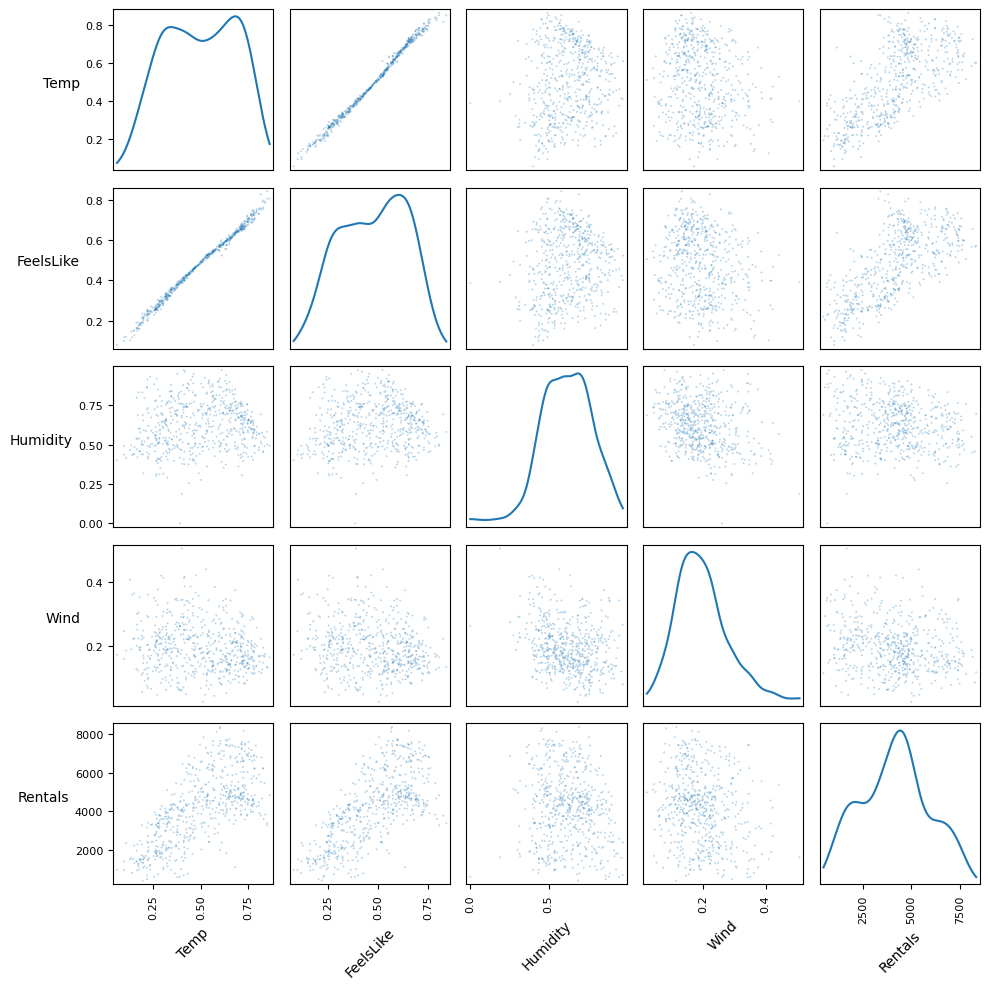

In [5]:
PLOTTING.scatter_matrix(df=train_df[CONTINUOUS + [TARGET]])

### Notes / Observations

Only the continuous attributes are plotted. The categorical codes are labels, and Q2B's box plots show Rentals at each of their levels.

- **Temp and FeelsLike fall on a single line,** so the two carry the same information.
- **Their Rentals panels rise, then level off,** which a straight line cannot follow. The interventions below test that shape.
- **Humidity and Wind are loose clouds against Rentals,** with no clear direction.

## Correlation

<Axes: title={'center': 'Pearson (lower) vs Spearman (upper) Correlation Matrix (train)'}>

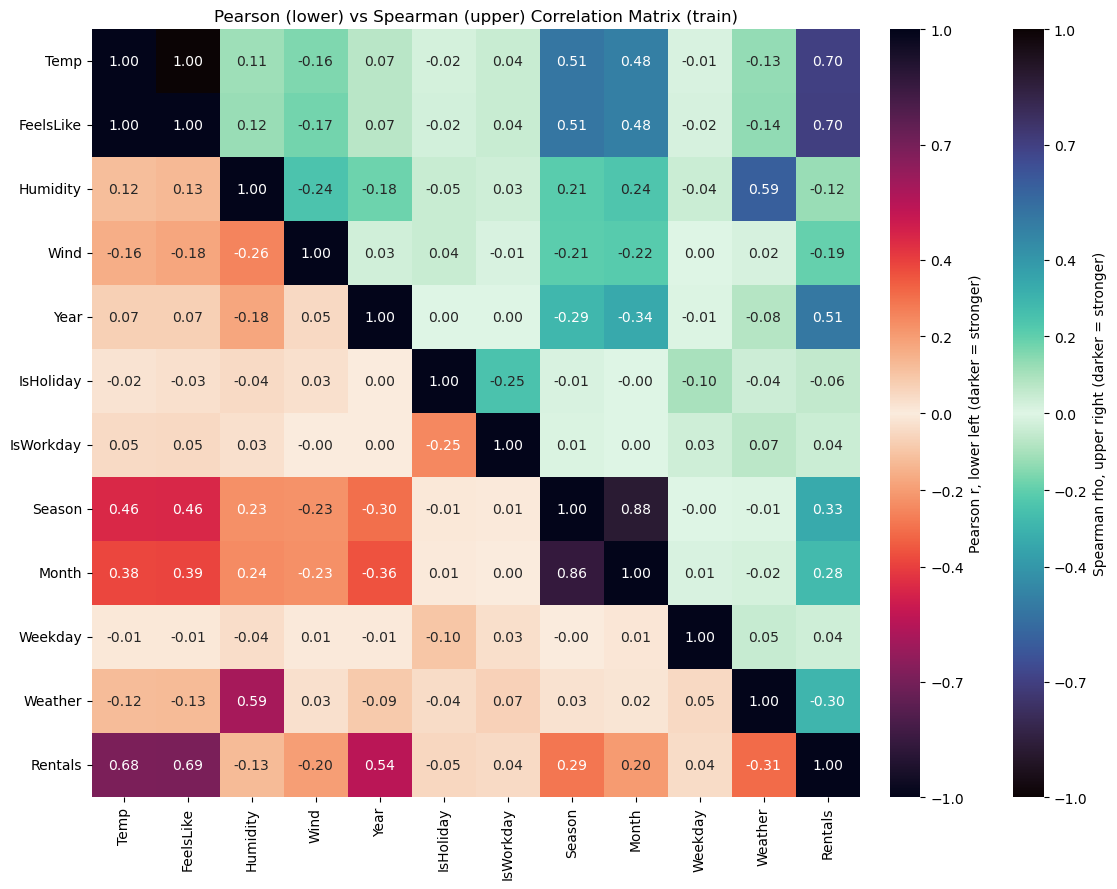

In [6]:
PLOTTING.correlation_matrix(
	pearson=train_df[ATTRIBUTES + [TARGET]].corr(),
	spearman=train_df[ATTRIBUTES + [TARGET]].corr(method='spearman'),
	title='Pearson (lower) vs Spearman (upper) Correlation Matrix (train)',
	figsize=(14, 9),
)

### Notes / Observations

A gap between Pearson r (lower left) and Spearman rho (upper right) points to a curved relationship. Pearson r measures how closely the points follow a straight line. Spearman rho is the same calculation on the ranks of the values, so it only asks whether one attribute keeps rising (or keeps falling) as the other rises, and ignores by how much. A relationship that keeps rising but bends still has its ranks in order, so rho stays high, while r drops because the points leave the straight line. The reverse gap (r larger in size than rho) points to a few far out values steering the straight line, because ranking removes how far out they are.

- **Strength with `Rentals` (Pearson):** FeelsLike (0.69), Temp (0.68) and Year (0.54) lead. Weather, Season, Month and Wind are weak (0.20 to 0.31 in size), and the other four are near zero.
- **Pearson understates Season and Month.** It reads the code as an amount, but Q2B found their Rentals means rise and then fall across the codes, and its level means R² (0.37 and 0.45) puts them next to the temperature pair (0.47 and 0.48). Spearman (0.33 and 0.28) reads the code order too.
- **The gap is small for Temp and FeelsLike, although both bend** (ex Temp 0.68 vs 0.70). The correlation matrix alone does not show the bend, so it has to be read from the scatter plots.
- **Year is tied to Month (-0.36) and Season (-0.30) by the split.** Q2B found that months 9 to 12 only have first-year rows in train.

### Collinearity

`collinearity_df` gives each pair of attributes one of two outcomes:

| `outcome` | When | What it means |
|---|---|---|
| `redundant: keep one, or use regularization` | \|r\| between the two attributes is above 0.7 | The two say close to the same thing. Drop one of them, or keep both and use a regularized model (Ridge, Lasso or Elastic Net). |
| `not redundant` | \|r\| is at or below 0.7 | The pair is not flagged. Each attribute carries enough of its own information to keep both. |

- **The sign is ignored.** A pair at r = -0.85 is as redundant as one at 0.85.
- **The check is strict and uses the rounded r.** A pair that rounds to exactly 0.700 is `not redundant`.
- **Only the redundant pairs are shown** (`filter=True`), so an empty table means no pair crossed the threshold. `filter=False` shows every pair. Fewer than 2 columns raises a `ValueError`.

In [7]:
STATISTICS.collinearity_df(df=train_df[ATTRIBUTES],
						  # feature_pearson_threshold=0.7, filter=True # defaults
)

,rows used,Pearson r between features,|r| between features > 0.7,outcome
Temp + FeelsLike,584,0.997,True,"redundant: keep one, or use regularization"
Season + Month,584,0.862,True,"redundant: keep one, or use regularization"


#### Combined Gain

`combination_gain_df` gives each pair or triple one of two outcomes:

| `outcome` | When | What it means |
|---|---|---|
| `keep together` | Cohen f² is at or above 0.15 | The added attribute explains enough of what the baseline leaves unexplained. The baseline is the best subset that leaves one attribute out, so dropping any other attribute would cost at least as much. |
| `baseline is enough` | Cohen f² is below 0.15 | The added attribute brings little that the baseline does not already have. The baseline alone does nearly as well. |

- **The outcome is about the added attribute.** The baseline is the subset, one attribute short, with the highest Pearson R. f² is what the left out attribute adds on top of it: (R² all features - R² baseline) / (1 - R² all features).
- **The check is inclusive and uses the rounded f².** An f² of exactly 0.150 is `keep together`.
- **Only Pearson R decides it.** The Spearman rho columns are shown next to it but do not change the outcome.
- **Only the `keep together` rows are shown** (`filter=True`), so an empty table means no combination reached the threshold. `filter=False` shows every combination. A `size` below 2 or above the number of columns raises a `ValueError`.

In [8]:
STATISTICS.combination_gain_df(df=train_df[CONTINUOUS + BINARY], target=train_df[TARGET],
							   # size=2, cohen_f2_threshold=0.15, filter=True # defaults
)

,rows used,baseline features,added feature,baseline Pearson R,all features Pearson R,Pearson R gain,baseline Spearman rho,all features Spearman rho,Spearman rho gain,cohen f²,cohen f² ≥ 0.15,outcome
FeelsLike + Year,584,FeelsLike,Year,0.690,0.847,0.157,0.703,0.845,0.142,0.852,True,keep together
Temp + Year,584,Temp,Year,0.685,0.843,0.158,0.699,0.842,0.143,0.835,True,keep together


In [9]:
STATISTICS.combination_gain_df(df=train_df[CONTINUOUS + BINARY], target=train_df[TARGET], size=3,
							   # cohen_f2_threshold=0.15, filter=True # defaults
)

,rows used,baseline features,added feature,baseline Pearson R,all features Pearson R,Pearson R gain,baseline Spearman rho,all features Spearman rho,Spearman rho gain,cohen f²,cohen f² ≥ 0.15,outcome


#### Notes / Observations

The gain tables list the pairs and triples where the last attribute added lifts the multiple correlation R with `Rentals` by a Cohen f² of at least 0.15. They are fit and scored on the same rows, so the gains are optimistic. They use the continuous and binary attributes only, since a multi-level code is not an amount.

- **Two redundant pairs:** Temp and FeelsLike (r = 0.997) and Season and Month (0.862), the only pairs above 0.7.
- **Year adds the most on top of temperature.** It lifts R from 0.690 to 0.847 next to FeelsLike (f² 0.852), and nearly as much next to Temp (f² 0.835). No other pair clears the threshold.
- **Nothing clears it as a third attribute.** The size 3 table is empty, so no triple gains that much over its best pair.

## Category Overlap

In [10]:
pd.crosstab(train_df["Month"], train_df["Season"])

Season,1,2,3,4
Month,,,,
1,62,0,0,0
2,57,0,0,0
3,40,22,0,0
4,0,60,0,0
5,0,62,0,0
6,0,40,20,0
7,0,0,62,0
8,0,0,37,0
9,0,0,22,8


In [11]:
pd.crosstab(train_df["Weekday"], [train_df["IsHoliday"], train_df["IsWorkday"]])

IsHoliday   0       1
IsWorkday   0   1   0
Weekday              
0          84   0   0
1           0  72  12
2           0  83   0
3           0  82   1
4           0  82   1
5           0  81   2
6          84   0   0

### Notes / Observations

- **Month is a finer version of Season.** 8 of the 12 months fall in a single season, and months 3, 6, 9 and 12 are split across two.
- **IsWorkday is fully determined by Weekday and IsHoliday.** Weekdays 0 and 6 are never working days (84 rows each). Weekdays 1 to 5 are working days except on the 16 holiday rows, and no row is both a holiday and a working day.
- **The correlation matrix does not show that dependence** (IsWorkday is 0.03 with Weekday and -0.25 with IsHoliday), since it is not a straight line relationship.

# Attribute Interventions

Interventions on a single attribute aimed at improving the attribute's linear relationship & predictability with the target

## Method

- **Rows:** no attribute has missing values, so every intervention uses all 584 train rows.
- **Folds:** every intervention is a `Pipeline` of a transform then `LinearRegression`, fit inside each training fold and scored on the same 20 folds (4-fold cross validation over the 5 `SEEDS`).
- **The folds are shuffled.** The train rows are consecutive days, so a validation day usually has training days on both sides of it. The scores compare shapes inside the training period and are optimistic for the days after it.
- **A, the baseline:** the attribute as it is stored, alone, `Rentals = a + b·x`. Every other intervention has to beat it. If the shape an intervention adds is not real, it ties with A. The Categorical Attributes section lists two exceptions.

**Noise threshold (Δrmse vs A)**

- Δ is the mean of the per-fold rmse differences d (intervention minus A). Negative means lower error than A.
- SE is the standard error of Δ. The folds share most of their training rows, so they are not independent results, and the SE is widened for that with the Nadeau and Bengio correction: `SE = sqrt(var(d) · (1/folds + n_test/n_train))`.
- `verdict`:
  - **within noise:** Δ is within 1 SE of 0, so A is kept as the simpler model.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE.

**Results**

- Each attribute ends with its findings, what to **Carry forward** and, where something tested is dropped, what to **Ignore**.
- Only **candidate** interventions carry forward, with t searched in each fold where there is a threshold. Every gain is a single attribute gain, so it has to hold up again once the other attributes are in the model.

## Continuous Attributes

A is the raw value. Each intervention is a threshold shape, scored two ways:

- **fixed** variants use the threshold t that Q2B reported. Q2B found it on all the training rows, so a fixed variant can look optimistic.
- **nested** variants search t inside each training fold (inner 4-fold CV, at least 5% of the fold's rows on each side of t), over the default grid unless the attribute's setup cell sets its own. The picked t never sees the validation fold.

An indicator is coded `1 if x < t else 0`, the mirror of Q2B's `1[x >= t]`. Alone in a linear regression the two give the same fit.

### Temp

Tests Q2B's rank 1 as B (a flat top hinge alone, with the bend near 0.58) and rank 2 as C (the raw value plus a hinge near 0.58).

In [12]:
temp_col = "Temp"
temp_df = train_df[[temp_col, TARGET]]
temp_X = temp_df[[temp_col]]
temp_y = temp_df[TARGET]

temp_folds = PIPELINES.make_folds(temp_X, seeds=SEEDS)
temp_results = {}

print(f"rows used: {len(temp_df)} of {len(train_df)}")
print(f"folds: {len(temp_folds)}")

rows used: 584 of 584
folds: 20


#### Intervention A | Baseline (raw)

In [13]:
temp_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=temp_X, y=temp_y, folds=temp_folds,
)
display(SCORING.results_df({k: temp_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,1308.145,0.456,0.0,NaN,baseline


#### Intervention B | Flat top hinge alone

`[max(0, t - x)]`

Targets the shape in Q2B's LOWESS, which climbs up to about 0.6 and is nearly flat above it: one slope below the bend and none above it.

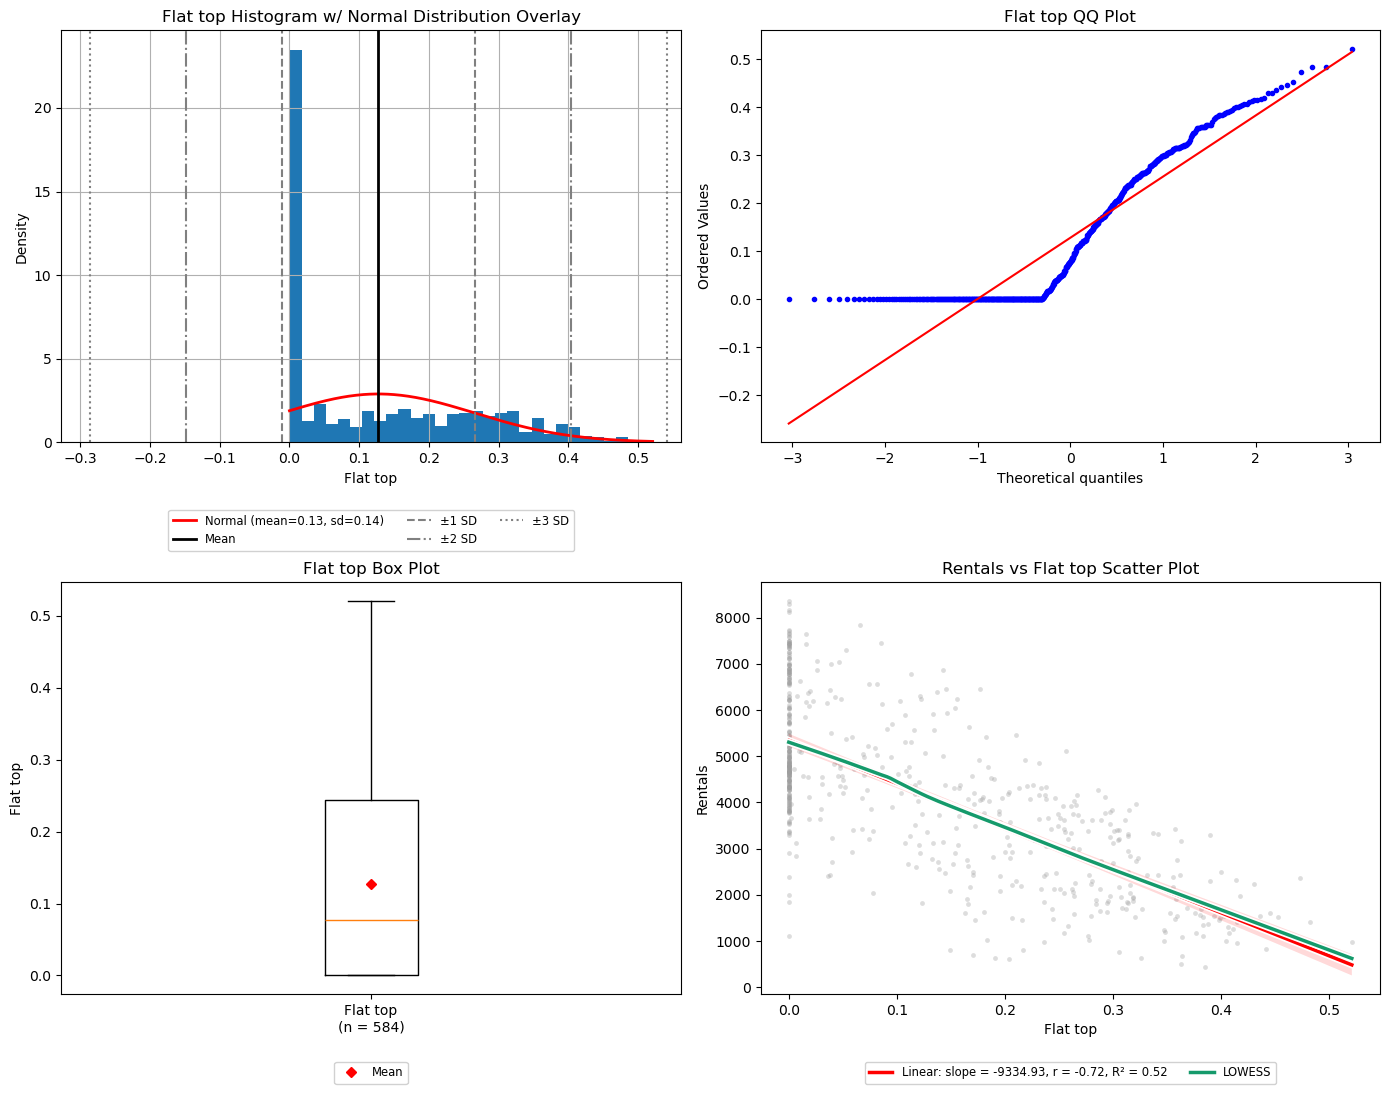

In [14]:
# fit on all temp_df rows, for illustration only (the scores below refit inside each training fold)
temp_b_df = pd.DataFrame(
	{"Flat top": np.ravel(FEATURES.LowHinge(t=0.58).fit_transform(temp_X)), TARGET: temp_y},
	index=temp_df.index,
)
# no threshold search: the rows at exactly 0 can make its hinge fit degenerate
PLOTTING.single_feature_plots(df=temp_b_df, feature="Flat top", target=TARGET);

In [15]:
temp_b_pipeline = Pipeline([("features", FEATURES.LowHinge(t=0.58)), ("model", LinearRegression())])

temp_results["B fixed (t=0.58)"] = PIPELINES.evaluate_pipeline(
	temp_b_pipeline,
	X=temp_X, y=temp_y, folds=temp_folds,
)
temp_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(temp_b_pipeline, param="features__t"),
	X=temp_X, y=temp_y, folds=temp_folds, return_estimator=True,
)
display(SCORING.results_df({k: temp_results[k] for k in ["A", "B fixed (t=0.58)", "B nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.58),1244.738,0.508,-63.406,18.923,candidate
B nested,1248.142,0.505,-60.003,19.071,candidate
A,1308.145,0.456,0.000,NaN,baseline


In [16]:
# threshold picked by the inner search in each of the 20 folds
temp_b_picked = FEATURES.picked_thresholds(temp_results["B nested"]["estimator"], param="features__t")
display(pd.Series(temp_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.55,2
0.57,11
0.59,7


#### Intervention C | Raw + hinge

`[x, max(0, x - t)]`

Keeps a separate slope above the bend, which Q2B's hinge fit puts at -358.32 against 9360.95 below it.

In [17]:
temp_c_pipeline = Pipeline([("features", FEATURES.HighHinge(t=0.58, keep_raw=True)), ("model", LinearRegression())])

temp_results["C fixed (t=0.58)"] = PIPELINES.evaluate_pipeline(
	temp_c_pipeline,
	X=temp_X, y=temp_y, folds=temp_folds,
)
temp_results["C nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(temp_c_pipeline, param="features__t"),
	X=temp_X, y=temp_y, folds=temp_folds, return_estimator=True,
)
display(SCORING.results_df({k: temp_results[k] for k in ["A", "C fixed (t=0.58)", "C nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
C fixed (t=0.58),1249.222,0.505,-58.923,20.747,candidate
C nested,1252.084,0.502,-56.060,21.863,candidate
A,1308.145,0.456,0.000,NaN,baseline


In [18]:
# threshold picked by the inner search in each of the 20 folds
temp_c_picked = FEATURES.picked_thresholds(temp_results["C nested"]["estimator"], param="features__t")
display(pd.Series(temp_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
0.55,2
0.57,10
0.59,6
0.61,2


#### Comparison

In [19]:
display(SCORING.results_df(temp_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.58),1244.738,0.508,-63.406,18.923,candidate
B nested,1248.142,0.505,-60.003,19.071,candidate
C fixed (t=0.58),1249.222,0.505,-58.923,20.747,candidate
C nested,1252.084,0.502,-56.060,21.863,candidate
A,1308.145,0.456,0.000,NaN,baseline


#### Results

- **The flat top is a clear gain.** rmse falls from 1308.145 to between 1244.738 and 1252.084 and r2 rises from 0.456 to between 0.502 and 0.508. All four variants are candidates.
- **A slope above the bend adds nothing.** C scores slightly behind B in both variants (1249.222 vs 1244.738 fixed, 1252.084 vs 1248.142 nested) with an extra column, so Rentals do not move with Temp above the bend.
- **The bend is stable.** B nested picked t between 0.55 and 0.59 in every fold (0.57 in 11 of the 20), around Q2B's 0.58.

**Carry forward**

- **B (flat top hinge alone, `[max(0, t - x)]`).** It replaces the raw column, so it adds no column.
- Only one of Temp and FeelsLike (r = 0.997) goes into a model.

**Ignore**

- **C (raw + hinge).** It is no better than B and costs an extra column.

### FeelsLike

Tests Q2B's rank 1 as B (a flat top hinge alone, with the bend near 0.60) and rank 2 as C (the raw value plus a hinge near 0.60).

In [20]:
feels_col = "FeelsLike"
feels_df = train_df[[feels_col, TARGET]]
feels_X = feels_df[[feels_col]]
feels_y = feels_df[TARGET]

feels_folds = PIPELINES.make_folds(feels_X, seeds=SEEDS)
feels_results = {}

print(f"rows used: {len(feels_df)} of {len(train_df)}")
print(f"folds: {len(feels_folds)}")

rows used: 584 of 584
folds: 20


#### Intervention A | Baseline (raw)

In [21]:
feels_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=feels_X, y=feels_y, folds=feels_folds,
)
display(SCORING.results_df({k: feels_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,1300.124,0.463,0.0,NaN,baseline


#### Intervention B | Flat top hinge alone

`[max(0, t - x)]`

Targets the shape in Q2B's LOWESS, which climbs up to about 0.6 and is flat above it: one slope below the bend and none above it.

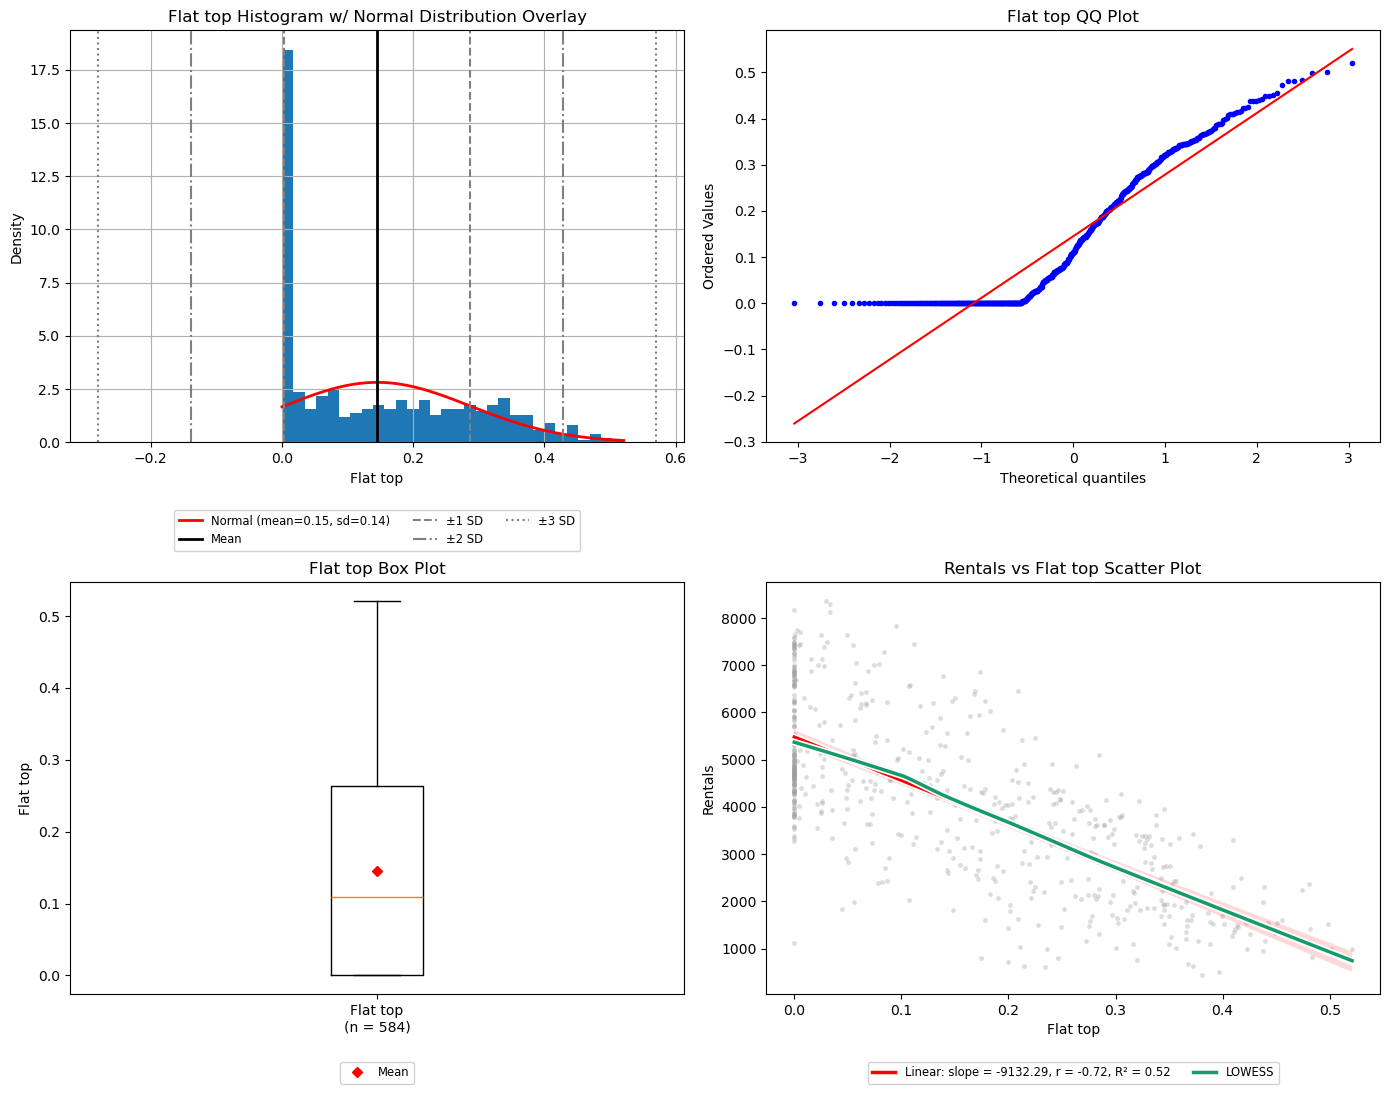

In [22]:
# fit on all feels_df rows, for illustration only (the scores below refit inside each training fold)
feels_b_df = pd.DataFrame(
	{"Flat top": np.ravel(FEATURES.LowHinge(t=0.60).fit_transform(feels_X)), TARGET: feels_y},
	index=feels_df.index,
)
# no threshold search: the rows at exactly 0 can make its hinge fit degenerate
PLOTTING.single_feature_plots(df=feels_b_df, feature="Flat top", target=TARGET);

In [23]:
feels_b_pipeline = Pipeline([("features", FEATURES.LowHinge(t=0.60)), ("model", LinearRegression())])

feels_results["B fixed (t=0.60)"] = PIPELINES.evaluate_pipeline(
	feels_b_pipeline,
	X=feels_X, y=feels_y, folds=feels_folds,
)
feels_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(feels_b_pipeline, param="features__t"),
	X=feels_X, y=feels_y, folds=feels_folds, return_estimator=True,
)
display(SCORING.results_df({k: feels_results[k] for k in ["A", "B fixed (t=0.60)", "B nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.60),1239.640,0.512,-60.483,12.765,candidate
B nested,1239.809,0.512,-60.315,15.128,candidate
A,1300.124,0.463,0.000,NaN,baseline


In [24]:
# threshold picked by the inner search in each of the 20 folds
feels_b_picked = FEATURES.picked_thresholds(feels_results["B nested"]["estimator"], param="features__t")
display(pd.Series(feels_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.57,12
0.59,8


#### Intervention C | Raw + hinge

`[x, max(0, x - t)]`

Lets the top slope downward, as Q2B's hinge fit does (-3086.80 above the bend against 9665.32 below it). Q2B flagged that downturn as resting on the few rows at the top.

In [25]:
feels_c_pipeline = Pipeline([("features", FEATURES.HighHinge(t=0.60, keep_raw=True)), ("model", LinearRegression())])

feels_results["C fixed (t=0.60)"] = PIPELINES.evaluate_pipeline(
	feels_c_pipeline,
	X=feels_X, y=feels_y, folds=feels_folds,
)
feels_results["C nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(feels_c_pipeline, param="features__t"),
	X=feels_X, y=feels_y, folds=feels_folds, return_estimator=True,
)
display(SCORING.results_df({k: feels_results[k] for k in ["A", "C fixed (t=0.60)", "C nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
C fixed (t=0.60),1237.651,0.514,-62.473,20.242,candidate
C nested,1243.430,0.509,-56.694,21.450,candidate
A,1300.124,0.463,0.000,NaN,baseline


In [26]:
# threshold picked by the inner search in each of the 20 folds
feels_c_picked = FEATURES.picked_thresholds(feels_results["C nested"]["estimator"], param="features__t")
display(pd.Series(feels_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
0.57,2
0.59,9
0.61,6
0.63,1
0.65,1
0.67,1


#### Comparison

In [27]:
display(SCORING.results_df(feels_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
C fixed (t=0.60),1237.651,0.514,-62.473,20.242,candidate
B fixed (t=0.60),1239.640,0.512,-60.483,12.765,candidate
B nested,1239.809,0.512,-60.315,15.128,candidate
C nested,1243.430,0.509,-56.694,21.450,candidate
A,1300.124,0.463,0.000,NaN,baseline


#### Results

- **The flat top is a clear gain.** rmse falls from 1300.124 to between 1237.651 and 1243.430 and r2 rises from 0.463 to between 0.509 and 0.514. All four variants are candidates.
- **The downturn at the top does not hold up.** C leads only at Q2B's 0.60 (1237.651 vs 1239.640 for B). With t searched it falls behind B (1243.430 vs 1239.809), and its picks spread from 0.57 to 0.67.
- **The flat top's bend is stable.** B nested picked 0.57 or 0.59 in every fold, and it scores nearly the same as B fixed (1239.809 vs 1239.640).
- **FeelsLike is slightly ahead of Temp** in both the raw column (1300.124 vs 1308.145) and the nested flat top (1239.809 vs 1248.142). The gap is small and was not tested directly.

**Carry forward**

- **B (flat top hinge alone, `[max(0, t - x)]`).** It replaces the raw column, so it adds no column.
- **FeelsLike as the first choice of the redundant pair,** with Temp as the fallback.

**Ignore**

- **C (raw + hinge).** It only leads at a threshold found on all the training rows.

### Humidity

Tests Q2B's rank 1 as B (a hinge alone, with the bend near 0.70) and rank 2 as C (an indicator alone, with the step near 0.78).

In [28]:
hum_col = "Humidity"
hum_df = train_df[[hum_col, TARGET]]
hum_X = hum_df[[hum_col]]
hum_y = hum_df[TARGET]

hum_folds = PIPELINES.make_folds(hum_X, seeds=SEEDS)
hum_results = {}

print(f"rows used: {len(hum_df)} of {len(train_df)}")
print(f"folds: {len(hum_folds)}")

rows used: 584 of 584
folds: 20


#### Intervention A | Baseline (raw)

In [29]:
hum_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=hum_X, y=hum_y, folds=hum_folds,
)
display(SCORING.results_df({k: hum_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,1775.147,0.005,0.0,NaN,baseline


#### Intervention B | Hinge alone

`[max(0, x - t)]`

Targets the shape in Q2B's LOWESS, which rises gently up to about 0.65 and then falls steeply: flat below the bend and one falling slope above it.

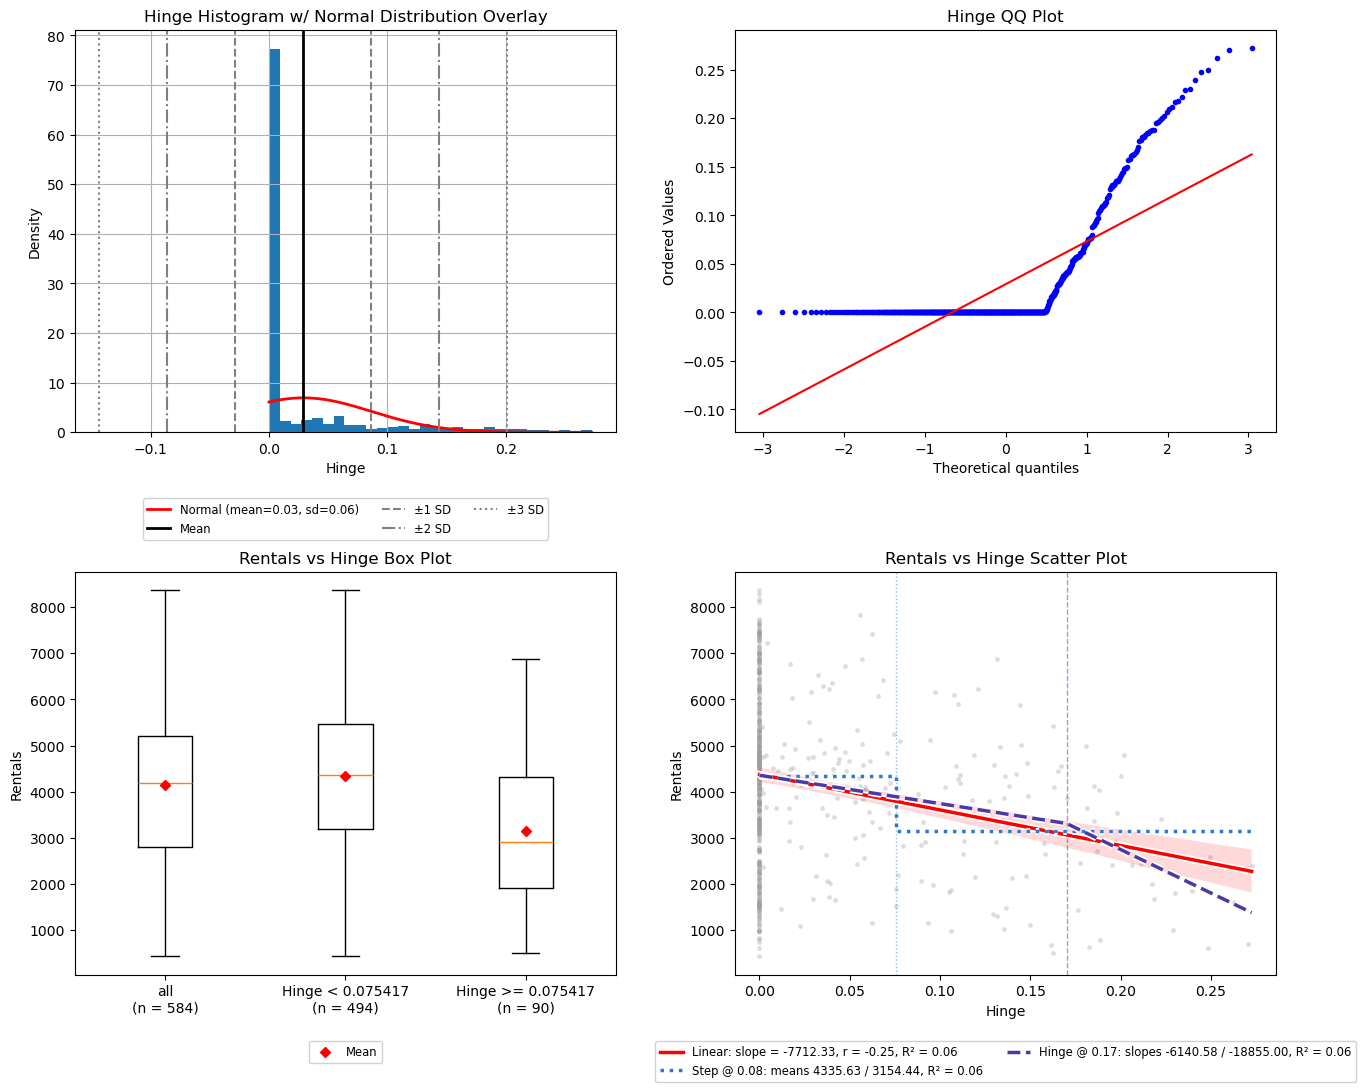

In [30]:
# fit on all hum_df rows, for illustration only (the scores below refit inside each training fold)
hum_b_df = pd.DataFrame(
	{"Hinge": np.ravel(FEATURES.HighHinge(t=0.70).fit_transform(hum_X)), TARGET: hum_y},
	index=hum_df.index,
)
# no LOWESS: most rows sit at exactly 0 in this column, where it cannot be computed
PLOTTING.single_feature_plots(df=hum_b_df, feature="Hinge", target=TARGET, threshold="auto", lowess=False);

In [31]:
hum_b_pipeline = Pipeline([("features", FEATURES.HighHinge(t=0.70)), ("model", LinearRegression())])

hum_results["B fixed (t=0.70)"] = PIPELINES.evaluate_pipeline(
	hum_b_pipeline,
	X=hum_X, y=hum_y, folds=hum_folds,
)
hum_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(hum_b_pipeline, param="features__t"),
	X=hum_X, y=hum_y, folds=hum_folds, return_estimator=True,
)
display(SCORING.results_df({k: hum_results[k] for k in ["A", "B fixed (t=0.70)", "B nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.70),1733.959,0.049,-41.188,12.091,candidate
B nested,1738.048,0.045,-37.099,9.584,candidate
A,1775.147,0.005,0.000,NaN,baseline


In [32]:
# threshold picked by the inner search in each of the 20 folds
hum_b_picked = FEATURES.picked_thresholds(hum_results["B nested"]["estimator"], param="features__t")
display(pd.Series(hum_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.67,1
0.71,3
0.75,12
0.77,2
0.81,1
0.83,1


#### Intervention C | Indicator alone

`[1 if x < t else 0]`

Targets the level shift in Q2B's box plot, where the rows at or above the step at 0.78 have lower Rentals than the rows below it.

In [33]:
hum_c_pipeline = Pipeline([("features", FEATURES.Indicator(t=0.78)), ("model", LinearRegression())])

hum_results["C fixed (t=0.78)"] = PIPELINES.evaluate_pipeline(
	hum_c_pipeline,
	X=hum_X, y=hum_y, folds=hum_folds,
)
hum_results["C nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(hum_c_pipeline, param="features__t"),
	X=hum_X, y=hum_y, folds=hum_folds, return_estimator=True,
)
display(SCORING.results_df({k: hum_results[k] for k in ["A", "C fixed (t=0.78)", "C nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
C fixed (t=0.78),1744.762,0.037,-30.385,14.703,candidate
C nested,1755.382,0.026,-19.765,10.942,candidate
A,1775.147,0.005,0.000,NaN,baseline


In [34]:
# threshold picked by the inner search in each of the 20 folds
hum_c_picked = FEATURES.picked_thresholds(hum_results["C nested"]["estimator"], param="features__t")
display(pd.Series(hum_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
0.77,8
0.79,1
0.83,2
0.85,8
0.87,1


#### Comparison

In [35]:
display(SCORING.results_df(hum_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.70),1733.959,0.049,-41.188,12.091,candidate
B nested,1738.048,0.045,-37.099,9.584,candidate
C fixed (t=0.78),1744.762,0.037,-30.385,14.703,candidate
C nested,1755.382,0.026,-19.765,10.942,candidate
A,1775.147,0.005,0.000,NaN,baseline


#### Results

- **The hinge beats the raw value in both variants.** rmse falls from 1775.147 to 1733.959 (fixed) and 1738.048 (nested), and both are candidates.
- **The bend sits a little above Q2B's 0.70.** B nested picked 0.75 in 12 of the 20 folds, with every pick between 0.67 and 0.83.
- **The indicator is weaker and its step is not settled.** C is a candidate too, with a smaller gain than B (-19.765 vs -37.099 nested), and its picks split between 0.77 and 0.85, 8 folds each.
- **The attribute stays weak either way.** r2 only rises from 0.005 to 0.045 (B nested).

**Carry forward**

- **B (hinge alone, `[max(0, x - t)]`).** It replaces the raw column, so it adds no column.

**Ignore**

- **C (indicator alone).** It gains less than B with the same single column.

### Wind

Q2B's rank 1 is the raw value, which is A. Tests rank 2 as B (an indicator alone, with the step near 0.18). Rank 3 is to drop the attribute, which cannot be scored with a single attribute.

In [36]:
wind_col = "Wind"
wind_df = train_df[[wind_col, TARGET]]
wind_X = wind_df[[wind_col]]
wind_y = wind_df[TARGET]

# Wind spans a narrow range, so the nested search uses its own finer grid in place of FEATURES.THRESHOLD_GRID
wind_grid = np.round(np.arange(0.03, 0.501, 0.01), 2)

wind_folds = PIPELINES.make_folds(wind_X, seeds=SEEDS)
wind_results = {}

wind_x = wind_X[wind_col].to_numpy()
wind_guarded = [t for t in wind_grid if min(np.mean(wind_x < t), np.mean(wind_x >= t)) >= FEATURES.MIN_GROUP_FRAC]
print(f"rows used: {len(wind_df)} of {len(train_df)}")
print(f"folds: {len(wind_folds)}")
print(f"threshold grid after the 5% guard (all rows): {wind_guarded[0]} to {wind_guarded[-1]}")

rows used: 584 of 584
folds: 20
threshold grid after the 5% guard (all rows): 0.09 to 0.34


#### Intervention A | Baseline (raw)

In [37]:
wind_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=wind_X, y=wind_y, folds=wind_folds,
)
display(SCORING.results_df({k: wind_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,1757.714,0.023,0.0,NaN,baseline


#### Intervention B | Indicator alone

`[1 if x < t else 0]`

Targets the level shift in Q2B's box plot, where the rows at or above the step at 0.18 have lower Rentals than the rows below it.

In [38]:
wind_b_pipeline = Pipeline([("features", FEATURES.Indicator(t=0.18)), ("model", LinearRegression())])

wind_results["B fixed (t=0.18)"] = PIPELINES.evaluate_pipeline(
	wind_b_pipeline,
	X=wind_X, y=wind_y, folds=wind_folds,
)
wind_results["B nested"] = PIPELINES.evaluate_pipeline(
	FEATURES.nested_threshold(wind_b_pipeline, param="features__t", grid=wind_grid),
	X=wind_X, y=wind_y, folds=wind_folds, return_estimator=True,
)
display(SCORING.results_df({k: wind_results[k] for k in ["A", "B fixed (t=0.18)", "B nested"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.18),1750.998,0.030,-6.717,11.678,within noise
A,1757.714,0.023,0.000,NaN,baseline
B nested,1759.677,0.021,1.963,10.795,within noise


In [39]:
# threshold picked by the inner search in each of the 20 folds
wind_b_picked = FEATURES.picked_thresholds(wind_results["B nested"]["estimator"], param="features__t")
display(pd.Series(wind_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.18,14
0.19,2
0.20,1
0.21,1
0.22,2


#### Comparison

In [40]:
display(SCORING.results_df(wind_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B fixed (t=0.18),1750.998,0.030,-6.717,11.678,within noise
A,1757.714,0.023,0.000,NaN,baseline
B nested,1759.677,0.021,1.963,10.795,within noise


#### Results

- **The indicator does not beat the raw value.** Both variants are within noise: B fixed is 6.717 below A's rmse and B nested is 1.963 above it, each well inside 1 SE (11.678 and 10.795).
- **The step is where Q2B put it, but it adds nothing.** B nested picked 0.18 in 14 of the 20 folds and never above 0.22.
- **The attribute is weak either way.** r2 is 0.023 for A and 0.021 to 0.030 for B.

**Carry forward**

- **A (the raw value, untreated),** Q2B's rank 1.
- **Dropping the attribute,** Q2B's rank 3, as an option to test once the other attributes are in the model.

**Ignore**

- **B (indicator alone).** It is within noise in both variants.

## Categorical Attributes

- **A is the code used as a number,** which gives the attribute one slope across its codes.
- **An intervention is an encoding of the levels,** so there is no threshold and no fixed or nested variant.
- **Season and Month are scored with `Year` in every pipeline,** A included. Q2B found that Season 4 and months 9 to 12 only have first-year rows in train, so without `Year` their columns absorb the lower first year. Their scores include Year's share and are not comparable with the other attributes' scores.
- **Year, Weekday, IsWorkday and IsHoliday have no encoding to test.** Each is scored as it is against a model that predicts the mean.

### Season

Tests Q2B's suggestion as B (one-hot encoding).

In [41]:
season_col = "Season"
season_df = train_df[[season_col, "Year", TARGET]]
season_X = season_df[[season_col, "Year"]]
season_y = season_df[TARGET]

season_folds = PIPELINES.make_folds(season_X, seeds=SEEDS)
season_results = {}

print(f"rows used: {len(season_df)} of {len(train_df)}")
print(f"folds: {len(season_folds)}")

rows used: 584 of 584
folds: 20


#### Intervention A | Baseline (code + Year)

In [42]:
season_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=season_X, y=season_y, folds=season_folds,
)
display(SCORING.results_df({k: season_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,1246.447,0.506,0.0,NaN,baseline


#### Intervention B | One-hot + Year

`[1 if Season = 2, 1 if Season = 3, 1 if Season = 4, Year]`

Gives each level its own mean. Q2B found the Rentals means rise and then fall across the codes (2,651 / 4,992 / 5,179 / 3,664), which one slope cannot follow.

In [43]:
season_b_pipeline = Pipeline([
	("features", ColumnTransformer(
		[("levels", OneHotEncoder(drop="first", sparse_output=False), [season_col])],
		remainder="passthrough",
	)),
	("model", LinearRegression()),
])

season_results["B"] = PIPELINES.evaluate_pipeline(
	season_b_pipeline,
	X=season_X, y=season_y, folds=season_folds,
)
display(SCORING.results_df({k: season_results[k] for k in ["A", "B"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B,1008.044,0.676,-238.403,28.819,candidate
A,1246.447,0.506,0.000,NaN,baseline


#### Comparison

In [44]:
display(SCORING.results_df(season_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B,1008.044,0.676,-238.403,28.819,candidate
A,1246.447,0.506,0.000,NaN,baseline


#### Results

- **One-hot is a large gain.** rmse falls from 1246.447 to 1008.044, a change of -238.403 against an SE of 28.819, and r2 rises from 0.506 to 0.676.
- **The gain is not a Year effect.** `Year` is in both pipelines, so the 238.403 drop in rmse is what a mean per level adds over one slope across the codes.

**Carry forward**

- **B (one-hot),** with `Year` in the model.
- Only one of Season and Month (r = 0.862) goes into a model.

### Month

Tests Q2B's rank 1 as B (one-hot encoding) and rank 2 as C (a cyclical encoding, the sine and cosine of the month).

In [45]:
month_col = "Month"
month_df = train_df[[month_col, "Year", TARGET]]
month_X = month_df[[month_col, "Year"]]
month_y = month_df[TARGET]

month_folds = PIPELINES.make_folds(month_X, seeds=SEEDS)
month_results = {}

print(f"rows used: {len(month_df)} of {len(train_df)}")
print(f"folds: {len(month_folds)}")

rows used: 584 of 584
folds: 20


#### Intervention A | Baseline (code + Year)

In [46]:
month_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=month_X, y=month_y, folds=month_folds,
)
display(SCORING.results_df({k: month_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,1299.806,0.464,0.0,NaN,baseline


#### Intervention B | One-hot + Year

`[1 if Month = 2, ..., 1 if Month = 12, Year]`

Gives each month its own mean, with 11 level columns. Q2B found the Rentals mean climbs from month 1 to month 6 and then drops to month 12, which one slope cannot follow.

In [47]:
month_b_pipeline = Pipeline([
	("features", ColumnTransformer(
		[("levels", OneHotEncoder(drop="first", sparse_output=False), [month_col])],
		remainder="passthrough",
	)),
	("model", LinearRegression()),
])

month_results["B"] = PIPELINES.evaluate_pipeline(
	month_b_pipeline,
	X=month_X, y=month_y, folds=month_folds,
)
display(SCORING.results_df({k: month_results[k] for k in ["A", "B"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B,912.127,0.736,-387.679,29.722,candidate
A,1299.806,0.464,0.000,NaN,baseline


#### Intervention C | Sine / cosine + Year

`[sin(2π·x / 12), cos(2π·x / 12), Year]`

Follows the same rise and fall with 2 columns in place of 11, and each month borrows from its neighbors. It assumes month 12 ends where month 1 starts.

In [48]:
month_c_pipeline = Pipeline([
	("features", ColumnTransformer(
		[("cycle", Q2_FEATURES.Cyclical(period=12), [month_col])],
		remainder="passthrough",
	)),
	("model", LinearRegression()),
])

month_results["C"] = PIPELINES.evaluate_pipeline(
	month_c_pipeline,
	X=month_X, y=month_y, folds=month_folds,
)
display(SCORING.results_df({k: month_results[k] for k in ["A", "C"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
C,985.850,0.691,-313.956,36.158,candidate
A,1299.806,0.464,0.000,NaN,baseline


#### Comparison

In [49]:
display(SCORING.results_df(month_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B,912.127,0.736,-387.679,29.722,candidate
C,985.850,0.691,-313.956,36.158,candidate
A,1299.806,0.464,0.000,NaN,baseline


#### Results

- **Both encodings are large gains, and both are candidates.** rmse falls from 1299.806 to 912.127 (B) and 985.850 (C).
- **One-hot is ahead of sine / cosine** (r2 0.736 vs 0.691), so one smooth wave does not fully describe the months once `Year` is in the model. The gap was not tested directly, and C gets there with 2 columns in place of 11.
- **Month is ahead of Season.** Both are scored with `Year` on the same folds, and both Month encodings have a lower rmse than Season's one-hot (1008.044).

**Carry forward**

- **B (one-hot),** with `Year` in the model.
- **C (sine / cosine)** as the alternative with fewer columns.
- **Month as the first choice of the redundant pair,** with Season as the fallback.

### Weather

Tests Q2B's rank 1 as B (one-hot encoding). Rank 2, the code as one numeric column, is A.

In [50]:
weather_col = "Weather"
weather_df = train_df[[weather_col, TARGET]]
weather_X = weather_df[[weather_col]]
weather_y = weather_df[TARGET]

weather_folds = PIPELINES.make_folds(weather_X, seeds=SEEDS)
weather_results = {}

print(f"rows used: {len(weather_df)} of {len(train_df)}")
print(f"folds: {len(weather_folds)}")

rows used: 584 of 584
folds: 20


#### Intervention A | Baseline (code as a number)

In [51]:
weather_results["A"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=weather_X, y=weather_y, folds=weather_folds,
)
display(SCORING.results_df({k: weather_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
A,1705.563,0.079,0.0,NaN,baseline


#### Intervention B | One-hot

`[1 if Weather = 2, 1 if Weather = 3]`

Gives each level its own mean. Q2B found the Rentals means fall in unequal steps across the codes (4,510 / 3,665 / 1,820), so one slope understates level 3.

In [52]:
weather_b_pipeline = Pipeline([("features", OneHotEncoder(drop="first", sparse_output=False)), ("model", LinearRegression())])

weather_results["B"] = PIPELINES.evaluate_pipeline(
	weather_b_pipeline,
	X=weather_X, y=weather_y, folds=weather_folds,
)
display(SCORING.results_df({k: weather_results[k] for k in ["A", "B"]}, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B,1700.256,0.085,-5.307,5.269,candidate
A,1705.563,0.079,0.000,NaN,baseline


#### Comparison

In [53]:
display(SCORING.results_df(weather_results, baseline="A"))

,rmse mean,r2 mean,Δrmse vs A,Δrmse SE,verdict
intervention,,,,,
B,1700.256,0.085,-5.307,5.269,candidate
A,1705.563,0.079,0.000,NaN,baseline


#### Results

- **One-hot only just clears the noise threshold.** It lowers rmse by 5.307 against an SE of 5.269, which makes it a candidate by a small margin.
- **The code as a number already gets most of it.** r2 is 0.079 for the code and 0.085 for one-hot. Q2B found the means fall in code order, so one slope gets the direction right, and the level it understates (level 3) has only 18 rows.

**Carry forward**

- **B (one-hot),** Q2B's rank 1.
- **A (the code as one numeric column)** as the fallback, with one column fewer, if B's gain does not hold up.

### Year, Weekday, IsWorkday and IsHoliday

Q2B's top suggestion is to keep Year and IsHoliday as they are and to drop Weekday and IsWorkday. A drop cannot be scored with a single attribute, so each of the four is compared with predicting the mean.

In [54]:
asis_cols = ["Year", "Weekday", "IsWorkday", "IsHoliday"]
asis_df = train_df[asis_cols + [TARGET]]
asis_y = asis_df[TARGET]

asis_folds = PIPELINES.make_folds(asis_df[asis_cols], seeds=SEEDS)
asis_results = {}

print(f"rows used: {len(asis_df)} of {len(train_df)}")
print(f"folds: {len(asis_folds)}")

rows used: 584 of 584
folds: 20


#### Baseline | Mean only

`Rentals = a`

Predicts the mean Rentals of the training fold for every row. An attribute that ties with it says nothing about Rentals on its own.

In [55]:
asis_results["Mean only"] = PIPELINES.evaluate_pipeline(
	Pipeline([("model", DummyRegressor(strategy="mean"))]),
	X=asis_df[asis_cols], y=asis_y, folds=asis_folds,
)
display(SCORING.results_df({k: asis_results[k] for k in ["Mean only"]}, baseline="Mean only"))

,rmse mean,r2 mean,Δrmse vs Mean only,Δrmse SE,verdict
intervention,,,,,
Mean only,1788.425,-0.011,0.0,NaN,baseline


#### Each attribute as it is

`Rentals = a + b·x`

One column per attribute and no encoding: the 0 / 1 value for Year, IsWorkday and IsHoliday, and the code as a number for Weekday.

In [56]:
for col in asis_cols:
	asis_results[col] = PIPELINES.evaluate_pipeline(
		Pipeline([("model", LinearRegression())]),
		X=asis_df[[col]], y=asis_y, folds=asis_folds,
	)

#### Comparison

In [57]:
display(SCORING.results_df(asis_results, baseline="Mean only"))

,rmse mean,r2 mean,Δrmse vs Mean only,Δrmse SE,verdict
intervention,,,,,
Year,1508.723,0.279,-279.701,37.589,candidate
Mean only,1788.425,-0.011,0.000,NaN,baseline
IsHoliday,1788.749,-0.011,0.324,3.388,within noise
IsWorkday,1790.221,-0.013,1.796,4.974,within noise
Weekday,1792.124,-0.015,3.700,6.411,within noise


#### Results

- **Year is a large gain over the mean.** rmse falls from 1788.425 to 1508.723, a change of -279.701 against an SE of 37.589, and r2 rises to 0.279.
- **Weekday, IsWorkday and IsHoliday say nothing about Rentals on their own.** All three are within noise of the mean, each with an rmse slightly above it (by 0.324 to 3.700) and an r2 below 0.

**Carry forward**

- **Year, as it is.** It also adds the most on top of temperature in the combination gain table.
- **Dropping Weekday and IsWorkday,** Q2B's top suggestion for both, to test once the other attributes are in the model. IsWorkday is also fully determined by Weekday and IsHoliday.
- **IsHoliday as it is,** Q2B's rank 1, with a drop as the option to test.